# Notebook 10 Part 3: Broadcast Joins and Join Optimization in PySpark



## 1. Why Can Joins Be Slow?

When Spark joins two large DataFrames, records having the same join key may need to move to the same partition.

This movement of data is called **shuffle**.

```text
Large shuffle = more network movement + more disk/memory work + slower job
```

A broadcast join can reduce this shuffle when one table is small.

## 2. What Is a Broadcast Join?

A broadcast join means:

```text
Spark copies the small DataFrame to every executor/worker.
```

Each worker can then join its large-table partition with the local copy of the small table.

Example:

```text
Large sales table + Small product lookup table
```

Instead of moving the huge sales table, Spark sends the small product table to workers.

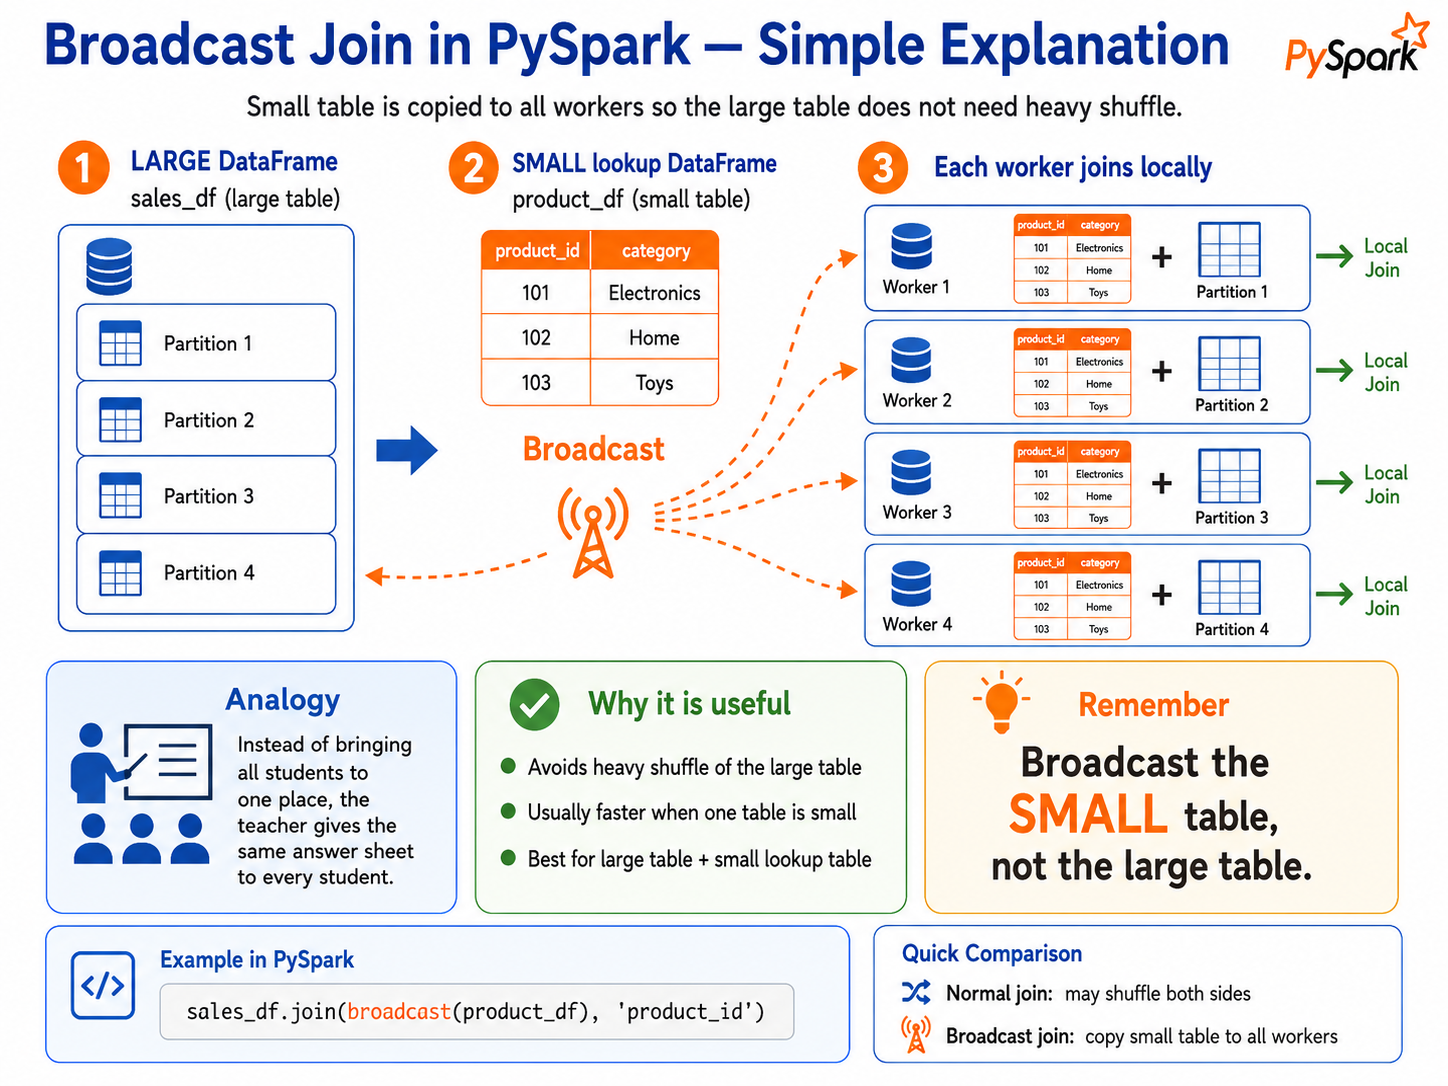

## 3. Normal Join vs Broadcast Join

| Point | Normal Join | Broadcast Join |
|---|---|---|
| Data movement | Can cause heavy shuffle | Small table is copied |
| Best case | Similar-sized tables | One table is small |
| Typical strategy | SortMergeJoin | BroadcastHashJoin |
| Memory need | Normal | Small table must fit in executor memory |

## 4. Windows Local Setup

In [1]:
import os
import sys
from pathlib import Path
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["SPARK_LOCAL_HOSTNAME"] = "localhost"

In [2]:
os.environ["HADOOP_HOME"] = "C:/hadoop"
os.environ["PATH"] = os.environ["HADOOP_HOME"] + "/bin;" + os.environ["PATH"]

In [3]:
print(Path("C:/hadoop/bin/winutils.exe").exists())
print(Path("C:/hadoop/bin/hadoop.dll").exists())

True
True


## 5. Create SparkSession

In [4]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("Broadcast_Joins") \
    .master("local[1]") \
    .config("spark.python.worker.reuse", "false") \
    .config("spark.driver.host", "127.0.0.1") \
    .config("spark.driver.bindAddress", "127.0.0.1") \
    .getOrCreate()


## 6. Create a Large Sales DataFrame

In [8]:
from pathlib import Path
base_path = Path("pyspark_broadcast_demo")
base_path.mkdir(exist_ok=True)
sales_csv = base_path / "sales.csv"

print(sales_csv.resolve())

E:\data\Documents\Data_Engineering\Module4-Pyspark\pyspark_broadcast_demo\sales.csv


In [10]:
sales_df = spark.read \
    .option("header", True) \
    .csv(str(sales_csv))

In [11]:
sales_df.show()

+--------+----------+------+
|order_id|product_id|amount|
+--------+----------+------+
|       1|        P2| 10500|
|       2|        P3| 11000|
|       3|        P4| 11500|
|       4|        P5| 12000|
|       5|        P1| 12500|
|       6|        P2| 13000|
|       7|        P3| 13500|
|       8|        P4| 14000|
|       9|        P5| 14500|
|      10|        P1| 15000|
|      11|        P2| 15500|
|      12|        P3| 16000|
|      13|        P4| 16500|
|      14|        P5| 17000|
|      15|        P1| 17500|
|      16|        P2| 18000|
|      17|        P3| 18500|
|      18|        P4| 19000|
|      19|        P5| 19500|
|      20|        P1| 20000|
+--------+----------+------+
only showing top 20 rows


## 7. Create a Small Product Lookup DataFrame

In [12]:
product_data = [
    ("P1", "Laptop", "Electronics"),
    ("P2", "Mobile", "Electronics"),
    ("P3", "Tablet", "Electronics"),
    ("P4", "Monitor", "Accessories"),
    ("P5", "Keyboard", "Accessories")
]

product_df = spark.createDataFrame(
    product_data,
    ["product_id", "product_name", "category"]
)

product_df.show()

+----------+------------+-----------+
|product_id|product_name|   category|
+----------+------------+-----------+
|        P1|      Laptop|Electronics|
|        P2|      Mobile|Electronics|
|        P3|      Tablet|Electronics|
|        P4|     Monitor|Accessories|
|        P5|    Keyboard|Accessories|
+----------+------------+-----------+



## 8. Normal Join

In [13]:
normal_join_df = sales_df.join(
    product_df,
    on="product_id",
    how="inner"
)

normal_join_df.show(5)

+----------+--------+------+------------+-----------+
|product_id|order_id|amount|product_name|   category|
+----------+--------+------+------------+-----------+
|        P1|   10000| 10000|      Laptop|Electronics|
|        P1|    9995| 57500|      Laptop|Electronics|
|        P1|    9990| 55000|      Laptop|Electronics|
|        P1|    9985| 52500|      Laptop|Electronics|
|        P1|    9980| 50000|      Laptop|Electronics|
+----------+--------+------+------------+-----------+
only showing top 5 rows


## 9. Check the Join Strategy

Use:

```python
normal_join_df.explain()
```

Look for terms such as:

```text
SortMergeJoin
BroadcastHashJoin
Exchange
```

`Exchange` usually indicates shuffle/data redistribution.

In [14]:
normal_join_df.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [product_id#38, order_id#37, amount#39, product_name#55, category#56]
   +- BroadcastHashJoin [product_id#38], [product_id#54], Inner, BuildLeft, false
      :- BroadcastExchange HashedRelationBroadcastMode(List(input[1, string, false]),false), [plan_id=202]
      :  +- Filter isnotnull(product_id#38)
      :     +- FileScan csv [order_id#37,product_id#38,amount#39] Batched: false, DataFilters: [isnotnull(product_id#38)], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/E:/data/Documents/Data_Engineering/Module4-Pyspark/pyspark_broad..., PartitionFilters: [], PushedFilters: [IsNotNull(product_id)], ReadSchema: struct<order_id:string,product_id:string,amount:string>
      +- Filter isnotnull(product_id#54)
         +- Scan ExistingRDD[product_id#54,product_name#55,category#56]




## 10. Force a Broadcast Join

Import `broadcast`:

In [15]:
from pyspark.sql.functions import broadcast

In [16]:
broadcast_join_df = sales_df.join(
    broadcast(product_df),
    on="product_id",
    how="inner"
)

broadcast_join_df.show(5)

+----------+--------+------+------------+-----------+
|product_id|order_id|amount|product_name|   category|
+----------+--------+------+------------+-----------+
|        P2|       1| 10500|      Mobile|Electronics|
|        P3|       2| 11000|      Tablet|Electronics|
|        P4|       3| 11500|     Monitor|Accessories|
|        P5|       4| 12000|    Keyboard|Accessories|
|        P1|       5| 12500|      Laptop|Electronics|
+----------+--------+------+------------+-----------+
only showing top 5 rows


## 11. Verify Broadcast Join

Run:

In [17]:
broadcast_join_df.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [product_id#38, order_id#37, amount#39, product_name#55, category#56]
   +- BroadcastHashJoin [product_id#38], [product_id#54], Inner, BuildRight, false
      :- Filter isnotnull(product_id#38)
      :  +- FileScan csv [order_id#37,product_id#38,amount#39] Batched: false, DataFilters: [isnotnull(product_id#38)], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/E:/data/Documents/Data_Engineering/Module4-Pyspark/pyspark_broad..., PartitionFilters: [], PushedFilters: [IsNotNull(product_id)], ReadSchema: struct<order_id:string,product_id:string,amount:string>
      +- BroadcastExchange HashedRelationBroadcastMode(List(input[0, string, false]),false), [plan_id=303]
         +- Filter isnotnull(product_id#54)
            +- Scan ExistingRDD[product_id#54,product_name#55,category#56]




In the physical plan, you should generally see:

```text
BroadcastHashJoin
BroadcastExchange
```

That confirms Spark is broadcasting the small DataFrame.

## 12. How Broadcast Join Works Internally

Imagine the large table has four partitions:

```text
sales partition 1
sales partition 2
sales partition 3
sales partition 4
```

Spark copies `product_df` to each worker.

```text
product_df → worker 1
product_df → worker 2
product_df → worker 3
product_df → worker 4
```

Each worker performs the join locally.

## 13. Why Is It Called Broadcast Hash Join?

Spark usually builds an in-memory lookup structure for the small table.

Example:

```text
P1 → Laptop
P2 → Mobile
P3 → Tablet
```

Then Spark quickly matches each large-table record with the lookup.

# 14. Auto Broadcast Join

Spark can automatically broadcast a small table.

Important configuration:

```text
spark.sql.autoBroadcastJoinThreshold
```

It defines the approximate table size below which Spark may automatically broadcast a table.

In [18]:
spark.conf.get("spark.sql.autoBroadcastJoinThreshold")

'10485760b'

The returned value is usually represented in bytes.

The exact default can vary by Spark version/configuration, so check your own Spark session.

## 15. Temporarily Set Auto Broadcast Threshold

In [19]:
spark.conf.set(
    "spark.sql.autoBroadcastJoinThreshold",
    5 * 1024 * 1024
)

spark.conf.get("spark.sql.autoBroadcastJoinThreshold")

'5242880'

This sets the threshold to approximately:

```text
5 MB
```

## 16. Disable Automatic Broadcast for Demonstration

In [20]:
spark.conf.set(
    "spark.sql.autoBroadcastJoinThreshold",
    -1
)

spark.conf.get("spark.sql.autoBroadcastJoinThreshold")

'-1'

`-1` means automatic broadcast join is disabled.


## 18. Restore a Reasonable Threshold

In [21]:
spark.conf.set(
    "spark.sql.autoBroadcastJoinThreshold",
    10 * 1024 * 1024
)

spark.conf.get("spark.sql.autoBroadcastJoinThreshold")

'10485760'

# 19. When Should We Use Broadcast Join?

Use broadcast join when:

```text
1. One DataFrame is small
2. The other DataFrame is large
3. Small DataFrame can fit comfortably in executor memory
4. You want to reduce join shuffle
```

Typical examples:

```text
Large transactions + small country lookup
Large sales + small product lookup
Large clickstream + small campaign table
Large customer activity + small segment mapping
```

# 20. When Should We NOT Use Broadcast Join?

Do not broadcast a large DataFrame.

Possible problems:

```text
High executor memory usage
Out-of-memory errors
Slow broadcast transfer
Poor performance
```

Important rule:

```text
Broadcast the small table, not the large table.
```

## 32. Stop SparkSession

In [ ]:
spark.stop()